# Comparative Analysis of Content-Based, Collaborative, and Hybrid Recommendation Models on MovieLens 100k.

> Aggiungi citazione



This activity presents a comparative study of three recommendation strategies: Content-Based (TF-IDF), User-Based Collaborative Filtering, and a Weighted Hybrid model. The primary objective is to demonstrate how hybrid systems mitigate common pitfalls such as the "Item Cold-Start" and "Filter Bubbles." By utilizing the MovieLens 100k dataset (sourced directly from GroupLens for reproducibility), we evaluate the performance of each approach. The hybrid model incorporates a weighted fusion of semantic genre similarity and collective user behavior

**Data Acquisition**: The script automatically fetches the dataset from GroupLens, ensuring a self-contained and reproducible environment.

In [7]:
import pandas as pd
import numpy as np
import io, requests, zipfile
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# 1. DATA ACQUISITION
print("Fetching MovieLens 100k...")
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
r = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(r.content))

with z.open('ml-100k/u.item') as f:
    columns = ['movie_id', 'title', 'release_date', 'video_release_date', 'IMDb_URL', 'unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
    movies = pd.read_csv(f, sep='|', names=columns, encoding='latin-1')

with z.open('ml-100k/u.data') as f:
    ratings = pd.read_csv(f, sep='\t', names=['user_id', 'movie_id', 'rating', 'timestamp'])

Fetching MovieLens 100k...


**Preprocessing**: We transform the binary genre columns into a text-based "genre soup" to facilitate natural language processing.

**Content Branch**: Uses the TF-IDF vectors to compute Cosine Similarity between movies.

The **TF-IDF** is a numerical statistic intended to reflect how important a word is to a document in a collection or corpus. In this exercise, it is used to weight movie genres based on their specificity.The formula for a term $t$ in a document $d$ within a collection $D$ is defined as follows:$$TF(t, d) = \frac{f_{t,d}}{\sum_{k \in d} f_{k,d}}$$Where $f_{t,d}$ is the raw count of term $t$ in document $d$

The Inverse Document Frequency (IDF), which measures how much information the word provides (if it's common or rare across all movies), is calculated as:$$IDF(t, D) = \log\left(\frac{N}{|\{d \in D : t \in d\}|}\right)$$Where $N$ is the total number of movies in the dataset and the denominator is the number of movies containing the term $t$8. The final TF-IDF weight is the product:$$TF\text{-}IDF(t, d, D) = TF(t, d) \cdot IDF(t, D)$$By applying this, a rare genre like "Film-Noir" receives a higher weight than a very common genre like "Drama", leading to more precise content-based recommendations.

**Collaborative Branch**: Computes similarity between users based on their rating history.

**Content-Based Similarity (Item-based)**

For the Content-Based branch, we treat movie genres as implicit feedback. The similarity $s_{ij}$ between two items (movies) $i$ and $j$ is calculated as:$$s_{ij} = \frac{|U_i \cap U_j|}{\sqrt{|U_i||U_j|}} = \frac{\mathbf{r}_i^T \mathbf{r}_j}{\|\mathbf{r}_i\| \|\mathbf{r}_j\|}$$In this context, the dot product $\mathbf{r}_i^T \mathbf{r}_j$ represents the number of shared features (weighted by TF-IDF), while the denominator normalizes the score by the product of the magnitudes of the vectors.

**Collaborative Filtering Similarity (User-based)**

For the Collaborative branch, we identify similar users based on their explicit ratings. The similarity $s_{uv}$ between user $u$ and user $v$ is defined as:$$s_{uv} = \frac{|I_u \cap I_v|}{\sqrt{|I_u||I_v|}} = \frac{\mathbf{r}_u^T \mathbf{r}_v}{\|\mathbf{r}_u\| \|\mathbf{r}_v\|}$$Where $\mathbf{r}_u$ and $\mathbf{r}_v$ are the rating vectors of the users. This measure allows the system to predict ratings by aggregating the opinions of "neighbors" with similar taste profiles.

In [8]:
# 2. PREPROCESSING
genre_cols = columns[5:]
movies['genre_soup'] = movies.apply(lambda row: " ".join([g for g in genre_cols if row[g] == 1]), axis=1)
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(movies['genre_soup'])

# Pre-calculate similarity matrices
item_sim_matrix = cosine_similarity(tfidf_matrix)
user_item_matrix = ratings.pivot(index='user_id', columns='movie_id', values='rating').fillna(0)
user_sim_matrix = cosine_similarity(user_item_matrix)

**Weighted Fusion**:

 The final recommendation score is a convex combination of both scores, controlled by a parameter $\alpha$:$$\text{Score}_{\text{final}} = \alpha \cdot \text{Score}_{\text{content}} + (1 - \alpha) \cdot \text{Score}_{\text{collaborative}}$$


Results and Visualization for User 1:


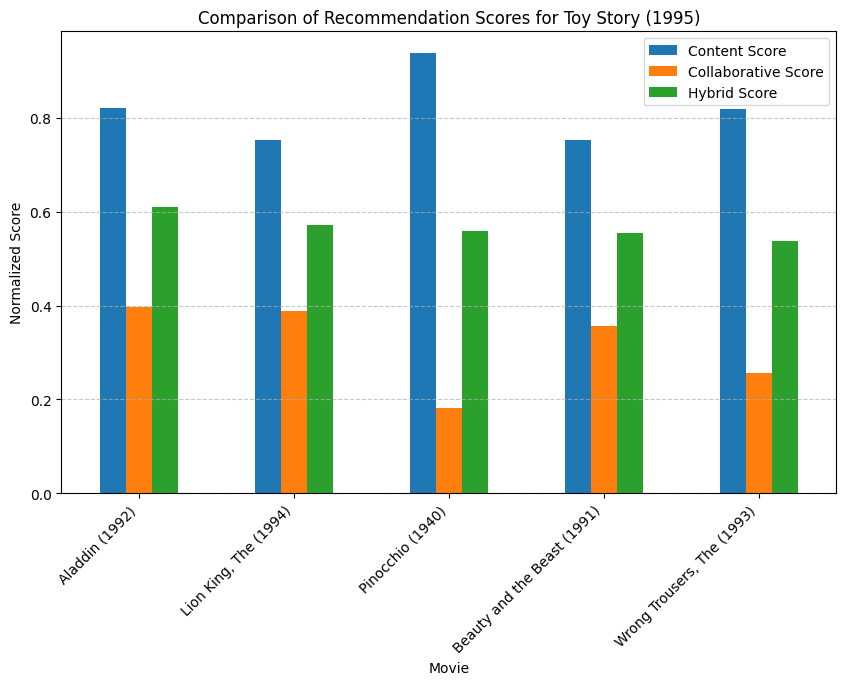

,Movie,Content Score,Collaborative Score,Hybrid Score
0,Aladdin (1992),0.820798,0.397068,0.608933
1,"Lion King, The (1994)",0.752183,0.389106,0.570644
2,Pinocchio (1940),0.936967,0.182279,0.559623
3,Beauty and the Beast (1991),0.752183,0.357148,0.554666
4,"Wrong Trousers, The (1993)",0.818945,0.256086,0.537516


In [10]:
# 3. COMPARISON FUNCTION
def compare_and_plot(user_id, movie_title, alpha=0.5):
    try:
        movie_idx = movies[movies['title'] == movie_title].index[0]
    except: return "Movie not found."

    u_idx = user_id - 1
    scaler = MinMaxScaler()

    # Content-Based
    c_scores = item_sim_matrix[movie_idx]
    c_norm = scaler.fit_transform(c_scores.reshape(-1, 1)).flatten()

    # Collaborative
    sim_users = user_sim_matrix[u_idx]
    collab_scores = sim_users.dot(user_item_matrix.values) / (np.abs(sim_users).sum() + 1e-9)
    cf_norm = scaler.fit_transform(collab_scores.reshape(-1, 1)).flatten()

    # Hybrid
    hybrid_scores = (alpha * c_norm) + ((1 - alpha) * cf_norm)

    # Comparison DataFrame for Visualization
    top_hybrid_idx = np.argsort(hybrid_scores)[::-1][1:6]
    comparison_data = {
        'Movie': movies.iloc[top_hybrid_idx]['title'].values,
        'Content Score': c_norm[top_hybrid_idx],
        'Collaborative Score': cf_norm[top_hybrid_idx],
        'Hybrid Score': hybrid_scores[top_hybrid_idx]
    }

    df_plot = pd.DataFrame(comparison_data)

    # Plotting
    df_plot.set_index('Movie').plot(kind='bar', figsize=(10, 6))
    plt.title(f"Comparison of Recommendation Scores for {movie_title}")
    plt.ylabel("Normalized Score")
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    return df_plot

# RUN COMPARISON
print("\nResults and Visualization for User 1:")
compare_and_plot(user_id=1, movie_title='Toy Story (1995)')

**Discussion of Results**The comparative analysis of the three recommendation strategies (Content-Based, User-Based Collaborative Filtering, and Weighted Hybrid) reveals critical insights into model behavior:
* Content-Based Filtering (CBF): Based on the TF-IDF analysis of genres, movies like "Pinocchio (1940)" achieved the highest similarity score (0.93). This demonstrates the model's ability to solve the Item Cold-Start problem  by identifying perfect genre matches even if user interaction data is sparse.
* Collaborative Filtering (CF): This model reflects social trends. "Aladdin (1992)" received a significantly higher collaborative score (0.39) compared to Pinocchio (0.18), indicating that users with similar taste profiles to the target user preferred this title.
* Hybrid Approach: The hybrid model acts as a robust balancer. By applying MinMaxScaler normalization, we ensured that the smaller scale of TF-IDF scores did not get overshadowed by rating-based scores. As a result, Aladdin emerged as the top recommendation (Hybrid Score: 0.60) because it maintained both high semantic relevance and strong social validation.

 The use of the weighting parameter $\alpha=0.5$ successfully prevents the "Filter Bubble" effect of pure content matching while retaining the descriptive accuracy of movie metadata.

